# Boston 311: Demand Forecasting with a ReAct Agent


Python calculates forecasts and validation metrics; the model selects tools and explains the results. Forecasts repeat 2024 monthly counts for 2025.

In [54]:
# Uncomment if these packages are missing in the selected kernel:
# %pip install langchain-classic langchain-core langchain-openai pandas matplotlib python-dotenv ipykernel

import sys
from importlib.metadata import version, PackageNotFoundError
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
for package in ["pandas", "langchain-classic", "langchain-core", "langchain-openai", "python-dotenv"]:
    try:
        print(package, version(package))
    except PackageNotFoundError:
        print(package, "NOT INSTALLED (needed for agent setup)")


Python: 3.11.16
Interpreter: /opt/anaconda3/envs/boston311/bin/python
pandas 3.1.0
langchain-classic 1.0.8
langchain-core 1.7.0
langchain-openai 1.7.2
python-dotenv 1.2.4


## 2. Load and validate the prepared monthly data

In [55]:
# Enter the absolute repository path if automatic discovery fails.
PROJECT_ROOT_OVERRIDE = ""

if PROJECT_ROOT_OVERRIDE:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
else:
    current = Path.cwd().resolve()
    PROJECT_ROOT = next(
        (p for p in [current, *current.parents]
         if (p / "data/processed/monthly_demand.csv").is_file()), None
    )
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Place this notebook inside boston311-crew-planner/notebooks, "
        "or set PROJECT_ROOT_OVERRIDE to your repository path."
    )
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
monthly_demand = pd.read_csv(
    PROCESSED_DIR / "monthly_demand.csv", parse_dates=["month"]
)
DEPARTMENT_CODES = {"PWDx", "BTDT", "PARK", "ISD"}
required = {"department", "month", "request_count"}
if not required.issubset(monthly_demand.columns):
    raise ValueError(f"Required columns: {sorted(required)}")
monthly_demand["request_count"] = pd.to_numeric(
    monthly_demand["request_count"], errors="raise"
)
assert len(monthly_demand) == 96, "Expected 96 historical rows"
assert monthly_demand["month"].notna().all()
assert monthly_demand["month"].dt.is_month_start.all()
assert not monthly_demand.duplicated(["department", "month"]).any()
assert set(monthly_demand["department"]) == DEPARTMENT_CODES
assert monthly_demand["request_count"].notna().all()
assert monthly_demand["request_count"].ge(0).all()
assert monthly_demand["request_count"].mod(1).eq(0).all()
expected = pd.MultiIndex.from_product(
    [sorted(DEPARTMENT_CODES), pd.date_range("2023-01-01", "2024-12-01", freq="MS")],
    names=["department", "month"],
)
actual = pd.MultiIndex.from_frame(monthly_demand[["department", "month"]])
assert len(expected.difference(actual)) == 0
print("Project:", PROJECT_ROOT)
print("Total requests:", int(monthly_demand["request_count"].sum()))
display(monthly_demand.head())


Project: /Users/nithyaa/Documents/Hackathon/boston311-crew-planner
Total requests: 558663


,department,month,request_count
0,BTDT,2023-01-01,5692
1,BTDT,2023-02-01,5316
2,BTDT,2023-03-01,6889
3,BTDT,2023-04-01,6143
4,BTDT,2023-05-01,6737


## 3. Compare historical seasonal patterns

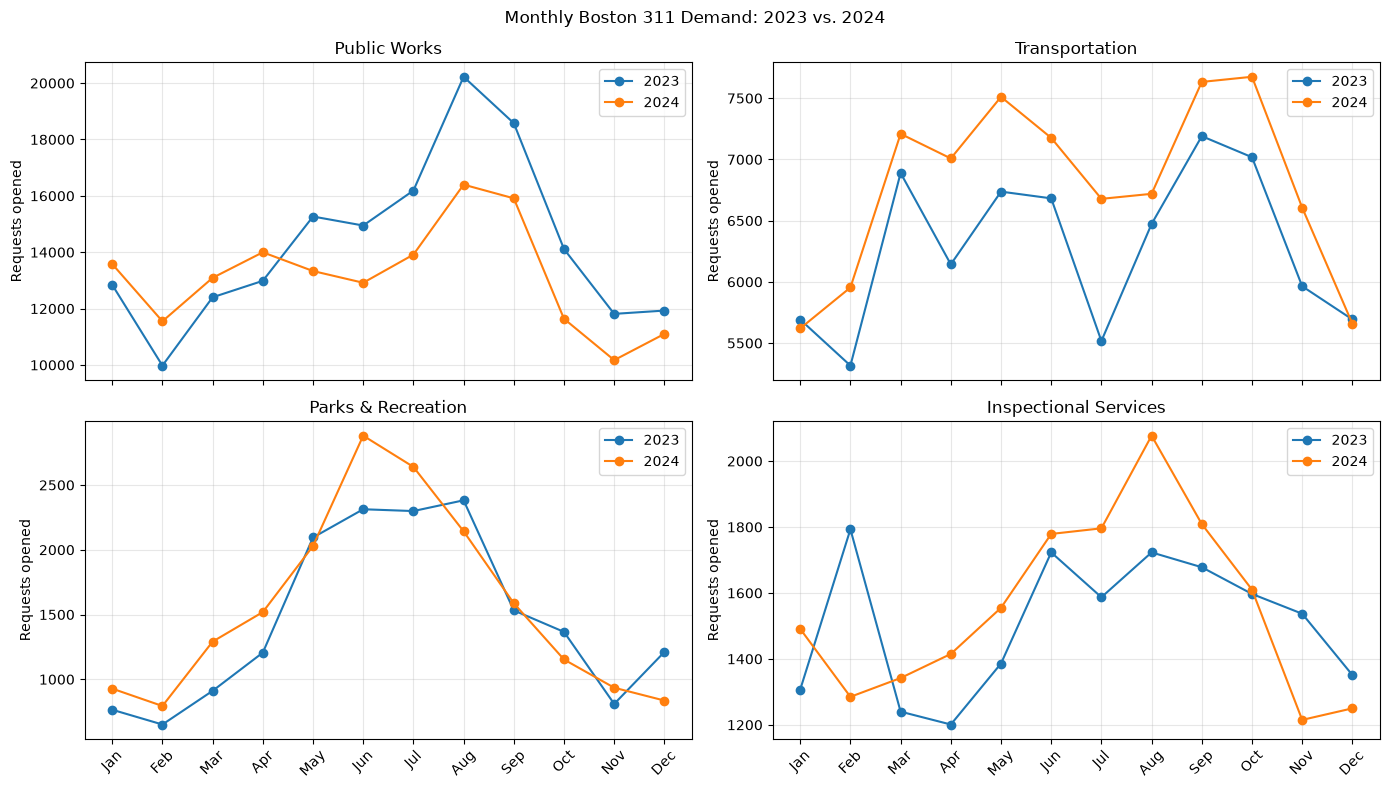

In [56]:
department_names = {
    "PWDx": "Public Works", "BTDT": "Transportation",
    "PARK": "Parks & Recreation", "ISD": "Inspectional Services",
}
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (department, name) in zip(axes.flat, department_names.items()):
    for year in [2023, 2024]:
        part = monthly_demand.loc[
            monthly_demand["department"].eq(department)
            & monthly_demand["month"].dt.year.eq(year)
        ].sort_values("month")
        ax.plot(part["month"].dt.month, part["request_count"], marker="o", label=str(year))
    ax.set_title(name)
    ax.set_ylabel("Requests opened")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], rotation=45)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Monthly Boston 311 Demand: 2023 vs. 2024")
plt.tight_layout()
plt.show()


## 4. Reusable forecasting and validation functions
Seasonal naive: each forecast equals the corresponding month of the prior year.
Validation predicts 2024 from 2023. The 2025 forecast uses 2024. No growth is extrapolated.


In [57]:
def get_department_history(data, department, year):
    """Return twelve valid monthly observations for one department and year."""
    if department not in DEPARTMENT_CODES:
        raise ValueError(f"Unknown department: {department}")
    history = data.loc[
        data["department"].eq(department) & data["month"].dt.year.eq(year),
        ["month", "request_count"],
    ].sort_values("month").copy()
    if (len(history) != 12
        or history["month"].dt.month.nunique() != 12
        or history["request_count"].isna().any()
        or history["request_count"].lt(0).any()):
        raise ValueError(f"Expected 12 valid monthly records for {department}, {year}")
    return history


def forecast_demand(data, department, target_year=2025):
    """Predict each month using the same month in the preceding year."""
    forecast = get_department_history(data, department, target_year - 1)
    forecast["month"] = forecast["month"] + pd.DateOffset(years=1)
    forecast = forecast.rename(columns={"request_count": "forecast_requests"})
    forecast.insert(0, "department", department)
    return forecast.reset_index(drop=True)


def validate_forecast(data, department, validation_year=2024):
    """Return historical MAE, WAPE percentage, and signed mean error."""
    predicted = forecast_demand(data, department, validation_year)
    actual = get_department_history(data, department, validation_year).rename(
        columns={"request_count": "actual_requests"}
    )
    comparison = predicted.merge(actual, on="month", validate="one_to_one")
    error = comparison["forecast_requests"] - comparison["actual_requests"]
    total = comparison["actual_requests"].sum()
    return {
        "department": department, "validation_year": validation_year,
        "months": len(comparison), "MAE": float(error.abs().mean()),
        "WAPE_percent": float(100 * error.abs().sum() / total) if total > 0 else None,
        "mean_error": float(error.mean()),
    }


## 5. Run the functions before connecting the agent

In [58]:
display(forecast_demand(monthly_demand, "BTDT"))
function_metrics = pd.DataFrame([
    validate_forecast(monthly_demand, department)
    for department in sorted(DEPARTMENT_CODES)
])
display(function_metrics.round(2))

# Check against the rounded results obtained in our earlier notebook.
expected_metrics = {
    "BTDT": (528.92, 7.79, -511.08),
    "ISD": (196.92, 12.69, -41.75),
    "PARK": (248.42, 15.91, -99.58),
    "PWDx": (1807.17, 13.76, 1138.17),
}
for row in function_metrics.to_dict("records"):
    expected_values = expected_metrics[row["department"]]
    for metric, expected_value in zip(["MAE", "WAPE_percent", "mean_error"], expected_values):
        assert abs(row[metric] - expected_value) < 0.02, (row["department"], metric)
print("Historical metrics match the previously reported results.")


,department,month,forecast_requests
0,BTDT,2025-01-01,5620
1,BTDT,2025-02-01,5954
2,BTDT,2025-03-01,7209
3,BTDT,2025-04-01,7008
4,BTDT,2025-05-01,7511
5,BTDT,2025-06-01,7176
6,BTDT,2025-07-01,6678
7,BTDT,2025-08-01,6719
8,BTDT,2025-09-01,7633
9,BTDT,2025-10-01,7675


,department,validation_year,months,MAE,WAPE_percent,mean_error
0,BTDT,2024,12,528.92,7.79,-511.08
1,ISD,2024,12,196.92,12.69,-41.75
2,PARK,2024,12,248.42,15.91,-99.58
3,PWDx,2024,12,1807.17,13.76,1138.17


Historical metrics match the previously reported results.


### Recorded findings
Transportation WAPE: 7.79%; ISD: 12.69%; Parks: 15.91%; Public Works: 13.76%.
Negative mean error means underprediction; positive means overprediction.
These are 2024 validation results, not 2025 accuracy. One validation year provides limited evidence.


## 6. Save all 48 forecasts and historical evaluation results

In [59]:
forecast_2025 = pd.concat([
    forecast_demand(monthly_demand, department)
    for department in sorted(DEPARTMENT_CODES)
], ignore_index=True)
assert len(forecast_2025) == 48
assert not forecast_2025.duplicated(["department", "month"]).any()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
forecast_2025.to_csv(PROCESSED_DIR / "forecast_2025.csv", index=False, date_format="%Y-%m-%d")
function_metrics.to_csv(OUTPUT_DIR / "forecast_validation_metrics.csv", index=False)
validation_parts = []
for department in sorted(DEPARTMENT_CODES):
    comparison = forecast_demand(monthly_demand, department, 2024).merge(
        get_department_history(monthly_demand, department, 2024).rename(columns={"request_count": "actual_requests"}),
        on="month", validate="one_to_one",
    ).rename(columns={"forecast_requests": "predicted_requests"})
    comparison["error"] = comparison["predicted_requests"] - comparison["actual_requests"]
    comparison["absolute_error"] = comparison["error"].abs()
    validation_parts.append(comparison)
pd.concat(validation_parts, ignore_index=True).to_csv(
    OUTPUT_DIR / "forecast_validation_2024.csv", index=False, date_format="%Y-%m-%d"
)
print("Saved forecasts and validation outputs.")


Saved forecasts and validation outputs.


## 7. Configure the LangChain model

In [60]:
#pip install langchain_classic

In [61]:
import os
import json
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_core.tools import Tool
from langchain_core.prompts import PromptTemplate
from langchain_classic.agents import create_react_agent, AgentExecutor

load_dotenv(PROJECT_ROOT / ".env", override=True)
if not os.environ.get("OPENAI_API_KEY", "").strip():
    raise ValueError("Set OPENAI_API_KEY in your repository-root .env.")
model_id = os.environ.get("OPENAI_MODEL", "").strip().removeprefix("openai:")
if not model_id:
    raise ValueError("Set OPENAI_MODEL to your available model ID in .env.")
forecast_llm = ChatOpenAI(model=model_id, timeout=60, max_retries=2)
print("Configured model:", model_id)


Configured model: gpt-4.1-mini


## 8. Wrap plain Python functions using `Tool(...)`
This follows the M06 MarketMaster lab. Each tool accepts one string: a department code. The wrappers validate it and return JSON text containing calculated numbers. No Python decorator or automatically inferred multi-argument tool schema is used.


In [62]:
def normalize_department(value):
    if not isinstance(value, str):
        raise ValueError("Department input must be a string.")
    code = value.strip().strip('"').strip("'")
    if code not in DEPARTMENT_CODES:
        raise ValueError("Use one department code: PWDx, BTDT, PARK, ISD.")
    return code


def forecast_department_tool(department):
    try:
        code = normalize_department(department)
        forecast = forecast_demand(monthly_demand, code, 2025)
        forecast["month"] = forecast["month"].dt.strftime("%Y-%m-%d")
        return json.dumps({
            "department": code, "forecast_year": 2025,
            "method": "seasonal_naive", "source_year": 2024,
            "annual_forecast": int(forecast["forecast_requests"].sum()),
            "monthly_forecasts": forecast.to_dict("records"),
            "assumption": "Repeats 2024 monthly counts without extrapolating growth or decline.",
        })
    except ValueError as exc:
        return json.dumps({"error": str(exc)})


def evaluate_department_tool(department):
    try:
        code = normalize_department(department)
        return json.dumps(validate_forecast(monthly_demand, code, 2024))
    except ValueError as exc:
        return json.dumps({"error": str(exc)})


forecast_tool = Tool(
    name="DemandForecast",
    func=forecast_department_tool,
    description="Calculate all twelve 2025 monthly demand forecasts from 2024 counts. Input is exactly one plain department code: PWDx, BTDT, PARK, or ISD. No JSON input. No staffing, other forecast years, or demand adjustments.",
)
validation_tool = Tool(
    name="ForecastValidation",
    func=evaluate_department_tool,
    description="Calculate historical 2024 validation metrics using 2023 counts: MAE, WAPE percent, mean error. Input is exactly one plain department code: PWDx, BTDT, PARK, or ISD. These are not 2025 accuracy results.",
)
forecast_tools = [forecast_tool, validation_tool]

# Direct numerical checks without an LLM call.
check = json.loads(validation_tool.invoke("BTDT"))
assert abs(check["WAPE_percent"] - 7.79) < 0.02
assert "error" in json.loads(forecast_tool.invoke("UNKNOWN"))
print("Direct tool checks passed.")


Direct tool checks passed.


## 9. Prompt engineering and ReAct agent
The model selects named actions; `AgentExecutor` executes them and supplies their observations back to the model. We show executed actions and tool observations, not private reasoning. Unlike the native tool-calling API, this class pattern uses a text action protocol and can have parsing errors. Iterations are bounded; malformed responses are retried through the executor.


In [63]:
forecast_prompt = PromptTemplate.from_template("""
You are a Boston 311 demand-forecasting assistant for 2025.
Public Works=PWDx; Transportation=BTDT; Parks and Recreation=PARK;
Inspectional Services=ISD.

Available tools:
{tools}

Use DemandForecast for forecast numbers and ForecastValidation for historical
validation. When asked for both, execute both tools for the requested department.
For all four departments, call the appropriate tools separately per department.
Use only numerical results returned by successful tool calls. Do not invent numbers
or use an error observation as valid data. Ask for clarification if department is missing.
Tools support only 2025 forecasts and 2024 historical validation.
Staffing, costs, selected-month changes and demand adjustments are not implemented here.
Explain that 2025 forecasts repeat corresponding 2024 counts with no growth adjustment.
Do not call WAPE an accuracy score; it is an error percentage. Negative mean error
means underprediction and positive means overprediction. Do not derive new metrics.
Unknown 2025 accuracy must not be confused with 2024 validation performance.

For an action, output only these two lines:
Action: one of [{tool_names}]
Action Input: a plain department code, e.g. BTDT

The executor supplies the Observation. Never invent an Observation.
After obtaining the required results, or to ask for clarification, output:
Final Answer: your answer

Never output an Action and Final Answer together in the same response.
Do not provide hidden reasoning. Show twelve monthly values when requested.

Question: {input}
{agent_scratchpad}
""")

react_forecast_agent = create_react_agent(
    llm=forecast_llm,
    tools=forecast_tools,
    prompt=forecast_prompt,
    stop_sequence=False,  # Same option used by the class MarketMaster example.
)
forecast_executor = AgentExecutor(
    agent=react_forecast_agent,
    tools=forecast_tools,
    verbose=False,
    handle_parsing_errors="Invalid action format. Return an Action with Action Input, or a Final Answer, never both.",
    max_iterations=12,
    return_intermediate_steps=True,
)
print("Course-style ReAct forecasting agent created.")


Course-style ReAct forecasting agent created.


## 10. Live demonstration
This cell makes API calls. Inspect tool selection, the returned observations, and the final answer. Numerical output remains authoritative in the Python results, not the generated narrative.

In [64]:
demo_result = forecast_executor.invoke({"input":
    "Forecast Transportation demand for 2025, show all twelve monthly values, "
    "and report the method's 2024 historical validation metrics."
})
for action, observation in demo_result["intermediate_steps"]:
    print("Executed tool:", action.tool)
    print("Input:", action.tool_input)
    print("Observation:", observation)
    print()

from IPython.display import Markdown, display
display(Markdown(demo_result["output"]))

successful_calls = {}
for action, observation in demo_result["intermediate_steps"]:
    if action.tool not in {"DemandForecast", "ForecastValidation"}:
        continue
    try:
        payload = json.loads(observation)
    except (TypeError, json.JSONDecodeError):
        continue
    if "error" not in payload and payload.get("department") == "BTDT":
        successful_calls[action.tool] = payload
assert {"DemandForecast", "ForecastValidation"}.issubset(successful_calls)
assert len(successful_calls["DemandForecast"]["monthly_forecasts"]) == 12
assert abs(successful_calls["ForecastValidation"]["WAPE_percent"] - 7.79) < 0.02
print("Both numerical tools executed successfully for BTDT. Review narrative for agreement.")


Executed tool: DemandForecast
Input: BTDT
Observation: {"department": "BTDT", "forecast_year": 2025, "method": "seasonal_naive", "source_year": 2024, "annual_forecast": 81447, "monthly_forecasts": [{"department": "BTDT", "month": "2025-01-01", "forecast_requests": 5620}, {"department": "BTDT", "month": "2025-02-01", "forecast_requests": 5954}, {"department": "BTDT", "month": "2025-03-01", "forecast_requests": 7209}, {"department": "BTDT", "month": "2025-04-01", "forecast_requests": 7008}, {"department": "BTDT", "month": "2025-05-01", "forecast_requests": 7511}, {"department": "BTDT", "month": "2025-06-01", "forecast_requests": 7176}, {"department": "BTDT", "month": "2025-07-01", "forecast_requests": 6678}, {"department": "BTDT", "month": "2025-08-01", "forecast_requests": 6719}, {"department": "BTDT", "month": "2025-09-01", "forecast_requests": 7633}, {"department": "BTDT", "month": "2025-10-01", "forecast_requests": 7675}, {"department": "BTDT", "month": "2025-11-01", "forecast_reques

The 2025 Transportation (BTDT) demand forecast monthly values are:  
- January: 5620  
- February: 5954  
- March: 7209  
- April: 7008  
- May: 7511  
- June: 7176  
- July: 6678  
- August: 6719  
- September: 7633  
- October: 7675  
- November: 6606  
- December: 5658  

These forecasts repeat the corresponding 2024 monthly counts without growth adjustment.  

The 2024 historical validation metrics for BTDT are:  
- MAE: 528.92 requests  
- WAPE: 7.79% error  
- Mean Error: -511.08 (underprediction bias)

Both numerical tools executed successfully for BTDT. Review narrative for agreement.


## 11. Optional boundary checks
Each invocation is a new question. Set True to run additional paid API calls. The checks below inspect tool selection and successful observations. They do not automatically validate the final narrative.


In [65]:
RUN_EXTRA_CHECKS = False
cases = [
    ("Forecast Parks demand for all months of 2025.", "DemandForecast", "PARK"),
    ("Report Public Works historical forecast validation for 2024.", "ForecastValidation", "PWDx"),
    ("Forecast demand for my department.", None, None),
    ("Forecast Transportation demand for 2026.", None, None),
]
if RUN_EXTRA_CHECKS:
    records = []
    for question, expected_tool, department in cases:
        try:
            response = forecast_executor.invoke({"input": question})
            calls = [(a.tool, a.tool_input, o) for a, o in response["intermediate_steps"] if a.tool in {"DemandForecast", "ForecastValidation"}]
            passed = not calls if expected_tool is None else any(
                name == expected_tool and json.loads(observation).get("department") == department
                and "error" not in json.loads(observation)
                for name, argument, observation in calls
            )
            records.append({"question": question, "tool_check_passed": passed, "calls": json.dumps(calls), "answer": response["output"], "error": ""})
        except Exception as exc:
            records.append({"question": question, "tool_check_passed": False, "calls": "", "answer": "", "error": type(exc).__name__})
    checks = pd.DataFrame(records)
    display(checks)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    checks.to_csv(OUTPUT_DIR / "forecast_react_evaluation.csv", index=False)
else:
    print("Extra checks not executed.")


Extra checks not executed.


## Scope, limitations, and integration
- The forecast is a deterministic seasonal baseline. Adding an agent does not improve its statistical accuracy.
- Only one historical validation year is available. Forecasting and validation arithmetic are supporting calculations, not LLM predictions.
- No RAG, custom LangGraph workflow, enforced final-response schema, staffing calculation, or native function-calling schema is claimed here.
- Crew planning remains in the separate JSON-extraction / LangGraph notebook. Resident intake remains separate too.
- Notebook execution counts and prior outputs may be stale. Restart the kernel and run all cells; keep the resulting outputs visible before submission.
- For parser errors, inspect executed actions/observations, the class prompt pattern, and the model's support. Do not treat a stopped executor as a completed forecast.

## AI-use disclosure
AI assisted with code fixes, and documentation.